# Payload-only FGSM / PGD Validation for MS-TCN-RetNet

Notebook này load checkpoint đã train của **MS-TCN-RetNet** và đánh giá trên:

- Clean test set
- FGSM payload-only attack
- PGD-10 payload-only attack
- PGD-20 payload-only attack
- PGD-50 payload-only attack

Threat model mặc định:
- chỉ perturb payload channels `2..9`
- giữ nguyên `arbitration_id`, `dlc`, `log_delta_t`, `id_freq_recent`
- payload được project trong L-infinity ball với bán kính `epsilon`
- payload được clamp về `[0, 1]`

Input feature order từ preprocessing hiện tại:

```text
0  arbitration_id_norm
1  dlc_norm
2  payload_0_norm255
3  payload_1_norm255
4  payload_2_norm255
5  payload_3_norm255
6  payload_4_norm255
7  payload_5_norm255
8  payload_6_norm255
9  payload_7_norm255
10 log_delta_t_norm
11 id_freq_recent_norm
```

In [1]:
# ============================================================
# 1. User configuration
# ============================================================

from pathlib import Path

# Project root should contain:
#   dataloader.py
#   networks/ms_tcn_retnet_torch.py
PROJECT_ROOT = Path("/home/hieutt/Retentive-Network")

DATA_DIR = PROJECT_ROOT / "data/2017-subaru-forester/preprocessed"

# Change this to your checkpoint path.
CHECKPOINT_PATH = PROJECT_ROOT / "save/ms_tcn_retnet_free_at/ms_tcn_retnet_free_at_best_test_adv_macro_f1.pth"

SAVE_DIR = PROJECT_ROOT / "eval_payload_adv"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda"       # "cuda" or "cpu"
GPU_ID = 0

BATCH_SIZE = 128
NUM_WORKERS = 0
PIN_MEMORY = True

# Attack config
EPSILON = "4/255"
PAYLOAD_INDICES = [2, 3, 4, 5, 6, 7, 8, 9]

# For PGD, a common choice is alpha = epsilon / 4.
PGD_ALPHA = "1/255"

# For quick debug, set e.g. MAX_EVAL_BATCHES = 10.
# For final results, keep it None.
MAX_EVAL_BATCHES = None

# Model fallback hyperparameters.
# If checkpoint contains args, checkpoint args are used first.
FALLBACK_MODEL_ARGS = {
    "hidden_dim": 64,
    "branch_dim": 32,
    "tcn_dim": 64,
    "tcn_depth": 2,
    "tcn_kernel_size": 3,
    "tcn_dropout": 0.1,
    "retention_dim": 64,
    "retention_depth": 2,
    "retention_heads": 4,
    "retention_dropout": 0.1,
    "ff_expansion": 4,
    "pool": "mean",
}

USE_CLASS_WEIGHTS_FOR_LOSS = False

In [2]:
# ============================================================
# 2. Imports and project modules
# ============================================================

import sys
import json
import random
from typing import Dict, List, Optional

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

sys.path.insert(0, str(PROJECT_ROOT))

from dataloader import build_all_dataloaders
from networks.ms_tcn_retnet_torch import MSTCNRetNet

try:
    from tqdm.notebook import tqdm
except Exception:
    from tqdm import tqdm

def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)

if DEVICE == "cuda":
    assert torch.cuda.is_available(), "CUDA is requested but not available."
    device = torch.device(f"cuda:{GPU_ID}")
    torch.cuda.set_device(device)
else:
    device = torch.device("cpu")

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(device))

Device: cuda:0
GPU: NVIDIA GeForce RTX 4090


In [3]:
# ============================================================
# 3. Helper functions
# ============================================================

def parse_float_or_fraction(value) -> float:
    s = str(value).strip()
    if "/" in s:
        a, b = s.split("/", 1)
        return float(a) / float(b)
    return float(s)

EPS = parse_float_or_fraction(EPSILON)
PGD_STEP = parse_float_or_fraction(PGD_ALPHA)

print("epsilon =", EPS)
print("pgd_alpha =", PGD_STEP)


def safe_torch_load(path, map_location="cpu"):
    try:
        return torch.load(path, map_location=map_location, weights_only=True)
    except Exception:
        return torch.load(path, map_location=map_location, weights_only=False)


def get_class_names(data_dir: Path, num_classes: int) -> List[str]:
    meta_path = data_dir / "metadata.json"
    if meta_path.exists():
        try:
            meta = json.loads(meta_path.read_text(encoding="utf-8"))
            class_map = meta.get("class_map", {})
            names = ["normal"]
            inv = {}
            for fname, cid in class_map.items():
                inv[int(cid)] = Path(fname).stem
            for c in range(1, num_classes):
                names.append(inv.get(c, f"class_{c}"))
            return names[:num_classes]
        except Exception as e:
            print("Could not parse metadata.json:", e)
    return ["normal"] + [f"class_{i}" for i in range(1, num_classes)]


def compute_class_weights(y: torch.Tensor, num_classes: int) -> torch.Tensor:
    counts = torch.bincount(y.cpu(), minlength=num_classes).float()
    counts = torch.clamp(counts, min=1.0)
    weights = counts.sum() / (num_classes * counts)
    return weights


def build_model_from_checkpoint_or_fallback(ckpt, input_dim: int, num_classes: int):
    ckpt_args = ckpt.get("args", {}) if isinstance(ckpt, dict) else {}

    def get_arg(name):
        return ckpt_args.get(name, FALLBACK_MODEL_ARGS[name])

    model = MSTCNRetNet(
        input_dim=input_dim,
        num_classes=num_classes,
        hidden_dim=int(get_arg("hidden_dim")),
        branch_dim=int(get_arg("branch_dim")),
        tcn_dim=int(get_arg("tcn_dim")),
        tcn_depth=int(get_arg("tcn_depth")),
        tcn_kernel_size=int(get_arg("tcn_kernel_size")),
        tcn_dropout=float(get_arg("tcn_dropout")),
        retention_dim=int(get_arg("retention_dim")),
        retention_depth=int(get_arg("retention_depth")),
        retention_heads=int(get_arg("retention_heads")),
        retention_dropout=float(get_arg("retention_dropout")),
        ff_expansion=int(get_arg("ff_expansion")),
        pool=str(get_arg("pool")),
    )
    return model


def compute_metrics(targets: np.ndarray, preds: np.ndarray, loss: float) -> Dict:
    acc = accuracy_score(targets, preds)
    macro_f1 = f1_score(targets, preds, average="macro", zero_division=0)
    weighted_f1 = f1_score(targets, preds, average="weighted", zero_division=0)
    cm = confusion_matrix(targets, preds)

    attack_mask = targets != 0
    if attack_mask.sum() > 0:
        fool_to_benign = float(np.mean(preds[attack_mask] == 0))
        attack_only_acc = float(np.mean(preds[attack_mask] == targets[attack_mask]))
    else:
        fool_to_benign = 0.0
        attack_only_acc = 0.0

    return {
        "loss": float(loss),
        "acc": float(acc),
        "macro_f1": float(macro_f1),
        "weighted_f1": float(weighted_f1),
        "fool_to_benign": fool_to_benign,
        "attack_only_acc": attack_only_acc,
        "preds": preds,
        "targets": targets,
        "cm": cm,
    }

epsilon = 0.01568627450980392
pgd_alpha = 0.00392156862745098


In [4]:
# ============================================================
# 4. Payload-only adversarial attack functions
# ============================================================

def make_feature_mask(x: torch.Tensor, indices: List[int]) -> torch.Tensor:
    mask = torch.zeros_like(x)
    mask[:, :, indices] = 1.0
    return mask


def project_payload_linf(
    x_adv: torch.Tensor,
    x_orig: torch.Tensor,
    epsilon: float,
    payload_indices: List[int],
) -> torch.Tensor:
    """
    Project adversarial payload into L_inf epsilon-ball around original payload.
    Non-payload features are restored exactly from original input.
    """
    x_proj = x_orig.clone()

    adv_payload = x_adv[:, :, payload_indices]
    orig_payload = x_orig[:, :, payload_indices]

    adv_payload = torch.max(
        torch.min(adv_payload, orig_payload + epsilon),
        orig_payload - epsilon,
    )
    adv_payload = adv_payload.clamp(0.0, 1.0)

    x_proj[:, :, payload_indices] = adv_payload
    return x_proj


def fgsm_attack(
    model: nn.Module,
    x: torch.Tensor,
    y: torch.Tensor,
    criterion: nn.Module,
    epsilon: float,
    payload_indices: List[int],
) -> torch.Tensor:
    """
    Payload-only FGSM attack.
    """
    model.zero_grad(set_to_none=True)
    mask = make_feature_mask(x, payload_indices)

    x_adv = x.detach().clone().requires_grad_(True)
    logits = model(x_adv)
    loss = criterion(logits, y)
    grad = torch.autograd.grad(loss, x_adv, retain_graph=False, create_graph=False)[0]

    x_adv = x_adv.detach() + epsilon * grad.sign() * mask
    x_adv = project_payload_linf(x_adv, x, epsilon, payload_indices)
    return x_adv.detach()


def pgd_attack(
    model: nn.Module,
    x: torch.Tensor,
    y: torch.Tensor,
    criterion: nn.Module,
    epsilon: float,
    alpha: float,
    steps: int,
    payload_indices: List[int],
    random_start: bool = True,
) -> torch.Tensor:
    """
    Payload-only PGD-k attack.
    """
    model.zero_grad(set_to_none=True)
    mask = make_feature_mask(x, payload_indices)

    x_adv = x.detach().clone()

    if random_start:
        random_delta = torch.empty_like(x_adv).uniform_(-epsilon, epsilon)
        x_adv = x_adv + random_delta * mask
        x_adv = project_payload_linf(x_adv, x, epsilon, payload_indices)

    for _ in range(steps):
        x_adv.requires_grad_(True)
        logits = model(x_adv)
        loss = criterion(logits, y)
        grad = torch.autograd.grad(loss, x_adv, retain_graph=False, create_graph=False)[0]

        x_adv = x_adv.detach() + alpha * grad.sign() * mask
        x_adv = project_payload_linf(x_adv, x, epsilon, payload_indices)

    return x_adv.detach()

In [5]:
# ============================================================
# 5. Load data
# ============================================================

bundle = build_all_dataloaders(
    data_dir=str(DATA_DIR),
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    train_drop_last=False,
    return_index=False,
)

train_dataset = bundle["train_dataset"]
test_loader = bundle["test_loader"]
val_loader = bundle["val_loader"]

input_shape = bundle["input_shape"]      # (T, C)
num_classes = bundle["num_classes"]
class_names = get_class_names(DATA_DIR, num_classes)

print("input_shape:", input_shape)
print("num_classes:", num_classes)
print("class_names:", class_names)
print("train samples:", len(train_dataset))

input_shape: (64, 12)
num_classes: 10
class_names: ['normal', 'combined', 'dos', 'fuzzing', 'gear', 'interval', 'rpm', 'speed', 'standstill', 'systematic']
train samples: 492204


In [6]:
# ============================================================
# 6. Load checkpoint and build model
# ============================================================

ckpt = safe_torch_load(CHECKPOINT_PATH, map_location="cpu")

model = build_model_from_checkpoint_or_fallback(
    ckpt=ckpt,
    input_dim=input_shape[1],
    num_classes=num_classes,
)

if isinstance(ckpt, dict) and "model_state_dict" in ckpt:
    state_dict = ckpt["model_state_dict"]
else:
    state_dict = ckpt

missing, unexpected = model.load_state_dict(state_dict, strict=False)

model = model.to(device)
model.eval()

print("Loaded checkpoint:", CHECKPOINT_PATH)
print("Missing keys:", missing)
print("Unexpected keys:", unexpected)

if isinstance(ckpt, dict):
    print("Checkpoint epoch:", ckpt.get("epoch", "N/A"))

Loaded checkpoint: /home/hieutt/Retentive-Network/save/ms_tcn_retnet_free_at/ms_tcn_retnet_free_at_best_test_adv_macro_f1.pth
Missing keys: []
Unexpected keys: []
Checkpoint epoch: 66


In [7]:
# ============================================================
# 7. Loss function
# ============================================================

if USE_CLASS_WEIGHTS_FOR_LOSS:
    class_weights = compute_class_weights(train_dataset.y, num_classes).to(device)
    print("class_weights:", class_weights)
else:
    class_weights = None

criterion = nn.CrossEntropyLoss(weight=class_weights)

In [8]:
# ============================================================
# 8. Evaluation functions
# ============================================================

@torch.no_grad()
def evaluate_clean(model, loader, criterion, device, max_batches: Optional[int] = None) -> Dict:
    model.eval()
    logits_all = []
    targets_all = []
    running_loss = 0.0
    n_samples = 0

    total = max_batches if max_batches is not None else len(loader)
    iterator = tqdm(enumerate(loader, start=1), total=total, desc="Clean eval")

    for batch_idx, batch in iterator:
        if max_batches is not None and batch_idx > max_batches:
            break

        X, y = batch[:2]
        X = X.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        logits = model(X)
        loss = criterion(logits, y)

        bs = X.size(0)
        running_loss += loss.item() * bs
        n_samples += bs

        logits_all.append(logits.detach().cpu())
        targets_all.append(y.detach().cpu())

    logits_all = torch.cat(logits_all, dim=0)
    targets_all = torch.cat(targets_all, dim=0)

    preds = logits_all.argmax(dim=1).numpy()
    targets = targets_all.numpy()

    return compute_metrics(targets, preds, running_loss / max(n_samples, 1))


def evaluate_adversarial(
    model,
    loader,
    criterion,
    device,
    attack_name: str,
    epsilon: float,
    payload_indices: List[int],
    pgd_steps: int = 20,
    pgd_alpha: float = 1/255,
    max_batches: Optional[int] = None,
) -> Dict:
    model.eval()
    logits_all = []
    targets_all = []
    running_loss = 0.0
    n_samples = 0

    total = max_batches if max_batches is not None else len(loader)
    iterator = tqdm(enumerate(loader, start=1), total=total, desc=f"{attack_name} eval")

    for batch_idx, batch in iterator:
        if max_batches is not None and batch_idx > max_batches:
            break

        X, y = batch[:2]
        X = X.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        with torch.enable_grad():
            if attack_name.lower() == "fgsm":
                X_adv = fgsm_attack(
                    model=model,
                    x=X,
                    y=y,
                    criterion=criterion,
                    epsilon=epsilon,
                    payload_indices=payload_indices,
                )
            elif attack_name.lower().startswith("pgd"):
                X_adv = pgd_attack(
                    model=model,
                    x=X,
                    y=y,
                    criterion=criterion,
                    epsilon=epsilon,
                    alpha=pgd_alpha,
                    steps=pgd_steps,
                    payload_indices=payload_indices,
                    random_start=True,
                )
            else:
                raise ValueError(f"Unsupported attack_name={attack_name}")

        with torch.no_grad():
            logits = model(X_adv)
            loss = criterion(logits, y)

        bs = X.size(0)
        running_loss += loss.item() * bs
        n_samples += bs

        logits_all.append(logits.detach().cpu())
        targets_all.append(y.detach().cpu())

    logits_all = torch.cat(logits_all, dim=0)
    targets_all = torch.cat(targets_all, dim=0)

    preds = logits_all.argmax(dim=1).numpy()
    targets = targets_all.numpy()

    return compute_metrics(targets, preds, running_loss / max(n_samples, 1))

In [9]:
# ============================================================
# 9. Run clean + FGSM + PGD-10/20/50 evaluation
# ============================================================

results = {}

clean_metrics = evaluate_clean(
    model=model,
    loader=test_loader,
    criterion=criterion,
    device=device,
    max_batches=MAX_EVAL_BATCHES,
)
results["Clean"] = clean_metrics

attack_configs = [
    {"name": "FGSM", "steps": 1,  "alpha": EPS},
    {"name": "PGD-10", "steps": 10, "alpha": PGD_STEP},
    {"name": "PGD-20", "steps": 20, "alpha": PGD_STEP},
    {"name": "PGD-50", "steps": 50, "alpha": PGD_STEP},
]

for cfg in attack_configs:
    attack_name = "fgsm" if cfg["name"] == "FGSM" else "pgd"
    metrics = evaluate_adversarial(
        model=model,
        loader=test_loader,
        criterion=criterion,
        device=device,
        attack_name=attack_name,
        epsilon=EPS,
        payload_indices=PAYLOAD_INDICES,
        pgd_steps=cfg["steps"],
        pgd_alpha=cfg["alpha"],
        max_batches=MAX_EVAL_BATCHES,
    )
    results[cfg["name"]] = metrics

print("Done.")

Clean eval:   0%|          | 0/1366 [00:00<?, ?it/s]

fgsm eval:   0%|          | 0/1366 [00:00<?, ?it/s]

pgd eval:   0%|          | 0/1366 [00:00<?, ?it/s]

pgd eval:   0%|          | 0/1366 [00:00<?, ?it/s]

pgd eval:   0%|          | 0/1366 [00:00<?, ?it/s]

Done.


In [10]:
# ============================================================
# 10. Summary table
# ============================================================

clean_f1 = results["Clean"]["macro_f1"]

summary_rows = []
for name, m in results.items():
    row = {
        "Setting": name,
        "Loss": m["loss"],
        "Accuracy": m["acc"],
        "Macro-F1": m["macro_f1"],
        "Weighted-F1": m["weighted_f1"],
        "F1 Drop vs Clean": clean_f1 - m["macro_f1"],
        "Attack-only Acc": m["attack_only_acc"],
        "Fool-to-Benign": m["fool_to_benign"],
    }
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)
summary_df

,Setting,Loss,Accuracy,Macro-F1,Weighted-F1,F1 Drop vs Clean,Attack-only Acc,Fool-to-Benign
0,Clean,0.004110,0.999468,0.998745,0.999467,0.000000,0.998066,0.001906
1,FGSM,0.008057,0.999027,0.997556,0.999027,0.001188,0.997042,0.002844
2,PGD-10,0.008239,0.998998,0.997492,0.998998,0.001253,0.996957,0.002930
3,PGD-20,0.008253,0.998993,0.997476,0.998992,0.001269,0.996928,0.002958
4,PGD-50,0.008258,0.998993,0.997476,0.998992,0.001269,0.996928,0.002958


In [11]:
# ============================================================
# 11. Save summary, reports, and confusion matrices
# ============================================================

summary_csv = SAVE_DIR / "payload_adv_eval_summary.csv"
summary_json = SAVE_DIR / "payload_adv_eval_summary.json"

summary_df.to_csv(summary_csv, index=False)

json_summary = {
    row["Setting"]: {
        "loss": float(row["Loss"]),
        "accuracy": float(row["Accuracy"]),
        "macro_f1": float(row["Macro-F1"]),
        "weighted_f1": float(row["Weighted-F1"]),
        "f1_drop_vs_clean": float(row["F1 Drop vs Clean"]),
        "attack_only_acc": float(row["Attack-only Acc"]),
        "fool_to_benign": float(row["Fool-to-Benign"]),
    }
    for _, row in summary_df.iterrows()
}

summary_json.write_text(json.dumps(json_summary, indent=2), encoding="utf-8")

for name, m in results.items():
    safe_name = name.lower().replace("-", "_").replace(" ", "_")

    np.save(SAVE_DIR / f"{safe_name}_confusion_matrix.npy", m["cm"])

    report = classification_report(
        m["targets"],
        m["preds"],
        target_names=class_names,
        zero_division=0,
        digits=4,
    )
    (SAVE_DIR / f"{safe_name}_classification_report.txt").write_text(report, encoding="utf-8")

print("Saved to:", SAVE_DIR)
print("Summary CSV:", summary_csv)
print("Summary JSON:", summary_json)

Saved to: /home/hieutt/Retentive-Network/eval_payload_adv
Summary CSV: /home/hieutt/Retentive-Network/eval_payload_adv/payload_adv_eval_summary.csv
Summary JSON: /home/hieutt/Retentive-Network/eval_payload_adv/payload_adv_eval_summary.json


In [12]:
# ============================================================
# 12. Display final reports
# ============================================================

for name, m in results.items():
    print("=" * 100)
    print(name)
    print("=" * 100)
    print(classification_report(
        m["targets"],
        m["preds"],
        target_names=class_names,
        zero_division=0,
        digits=4,
    ))

Clean
              precision    recall  f1-score   support

      normal     0.9995    0.9998    0.9997    139567
    combined     0.9985    0.9956    0.9971      8914
         dos     0.9992    0.9970    0.9981      1335
     fuzzing     1.0000    0.9988    0.9994      1727
        gear     1.0000    1.0000    1.0000      1409
    interval     0.9998    0.9999    0.9999     12721
         rpm     0.9996    0.9996    0.9996      2655
       speed     0.9987    0.9972    0.9980      3188
  standstill     1.0000    1.0000    1.0000      1235
  systematic     0.9975    0.9939    0.9957      1974

    accuracy                         0.9995    174725
   macro avg     0.9993    0.9982    0.9987    174725
weighted avg     0.9995    0.9995    0.9995    174725

FGSM
              precision    recall  f1-score   support

      normal     0.9993    0.9995    0.9994    139567
    combined     0.9972    0.9941    0.9956      8914
         dos     0.9992    0.9963    0.9977      1335
     fuzzing 

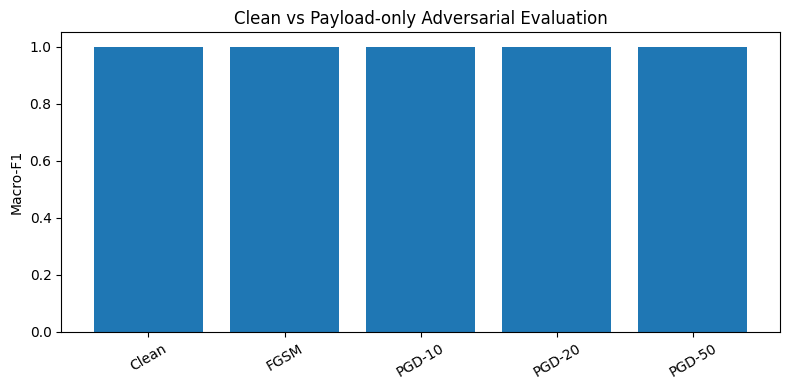

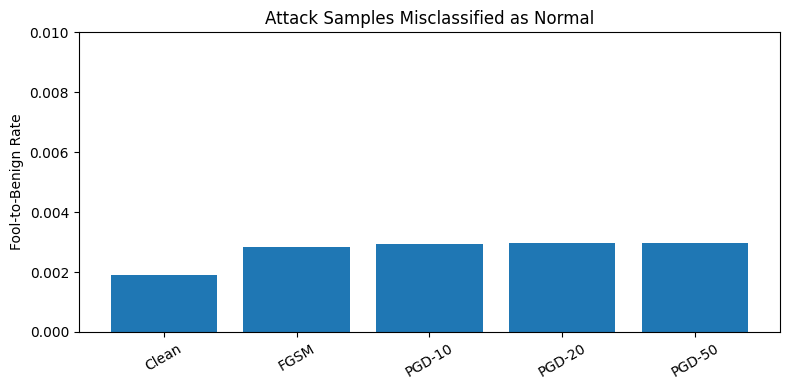

In [13]:
# ============================================================
# 13. Optional visualization
# ============================================================

import matplotlib.pyplot as plt

plot_df = summary_df.copy()

plt.figure(figsize=(8, 4))
plt.bar(plot_df["Setting"], plot_df["Macro-F1"])
plt.ylabel("Macro-F1")
plt.title("Clean vs Payload-only Adversarial Evaluation")
plt.xticks(rotation=30)
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.bar(plot_df["Setting"], plot_df["Fool-to-Benign"])
plt.ylabel("Fool-to-Benign Rate")
plt.title("Attack Samples Misclassified as Normal")
plt.xticks(rotation=30)
plt.ylim(0, max(0.01, float(plot_df["Fool-to-Benign"].max()) * 1.2))
plt.tight_layout()
plt.show()